In [1]:
import pandas as pd
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

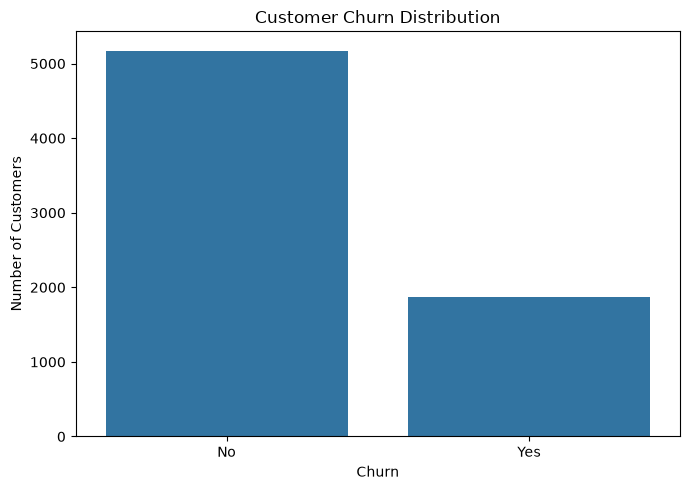

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../reports/figures/churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [3]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [4]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


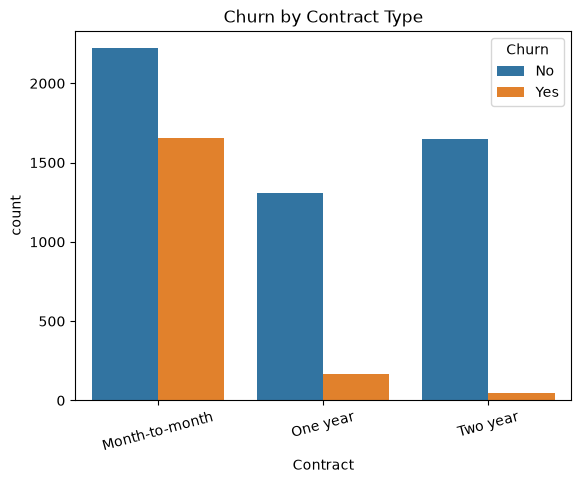

In [5]:
sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.show()

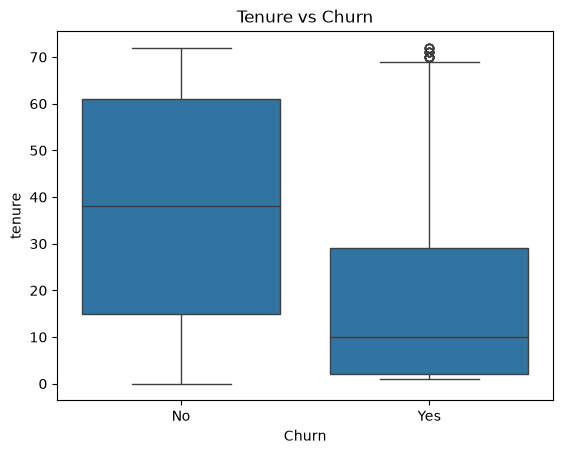

In [6]:
sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure vs Churn")
plt.show()

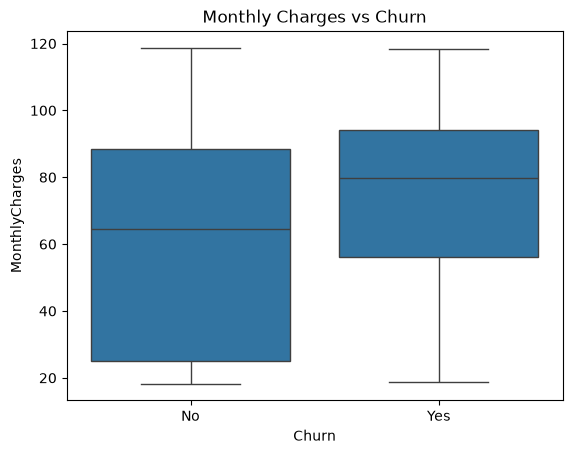

In [7]:
sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.show()

In [8]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


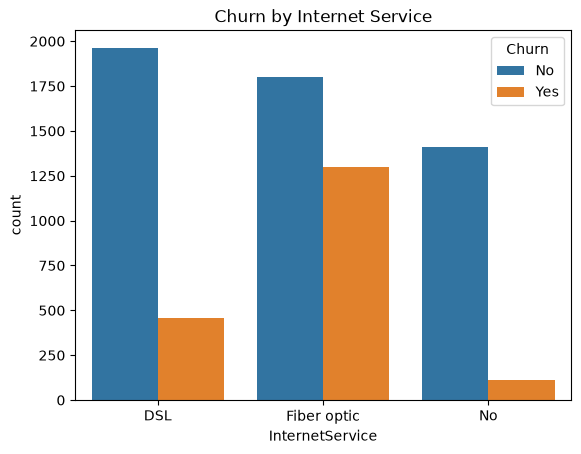

In [9]:
sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Churn by Internet Service")
plt.show()

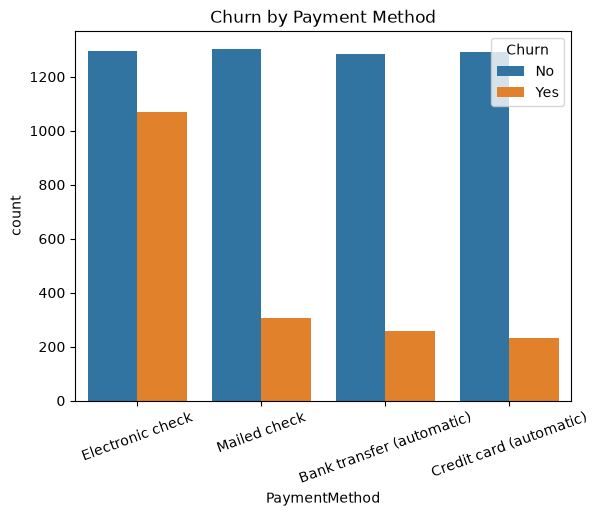

In [10]:
sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Churn by Payment Method")
plt.xticks(rotation=20)
plt.show()

In [11]:
numeric_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges"
]

In [12]:
df[numeric_columns].corr()

,SeniorCitizen,tenure,MonthlyCharges
SeniorCitizen,1.000000,0.016567,0.220173
tenure,0.016567,1.000000,0.247900
MonthlyCharges,0.220173,0.247900,1.000000


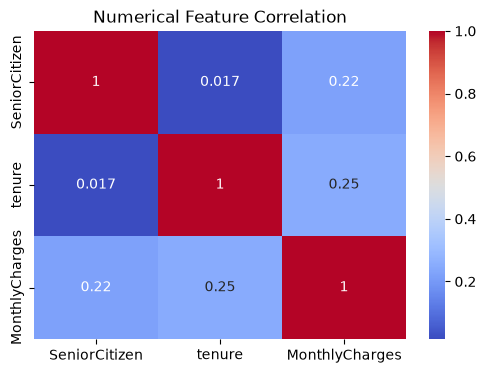

In [13]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    df[numeric_columns].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Numerical Feature Correlation")
plt.show()

In [14]:
categorical_columns = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

In [15]:
for col in categorical_columns:
    print(f"\n{'='*50}")
    print(f"{col}")
    print(f"{'='*50}")
    
    print(
        pd.crosstab(
            df[col],
            df["Churn"],
            normalize="index"
        ).round(3) * 100
    )


gender
Churn     No   Yes
gender            
Female  73.1  26.9
Male    73.8  26.2

Partner
Churn      No   Yes
Partner            
No       67.0  33.0
Yes      80.3  19.7

Dependents
Churn         No   Yes
Dependents            
No          68.7  31.3
Yes         84.5  15.5

PhoneService
Churn           No   Yes
PhoneService            
No            75.1  24.9
Yes           73.3  26.7

MultipleLines
Churn               No   Yes
MultipleLines               
No                75.0  25.0
No phone service  75.1  24.9
Yes               71.4  28.6

InternetService
Churn              No   Yes
InternetService            
DSL              81.0  19.0
Fiber optic      58.1  41.9
No               92.6   7.4

OnlineSecurity
Churn                  No   Yes
OnlineSecurity                 
No                   58.2  41.8
No internet service  92.6   7.4
Yes                  85.4  14.6

OnlineBackup
Churn                  No   Yes
OnlineBackup                   
No                   60.1  39.9
No int

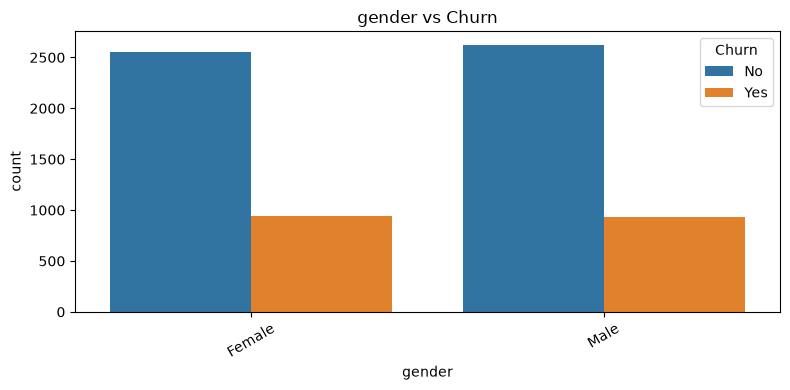

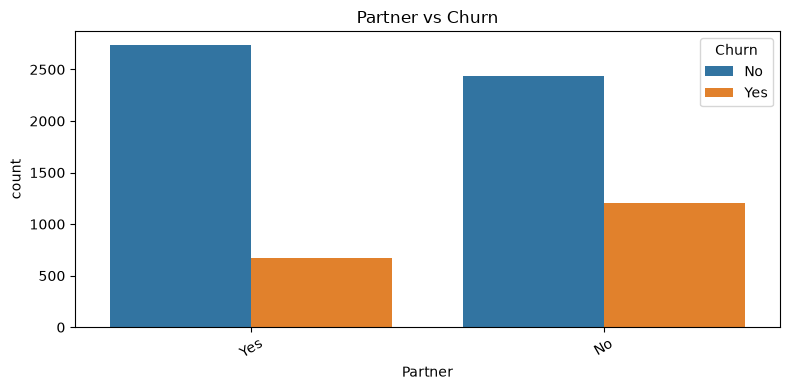

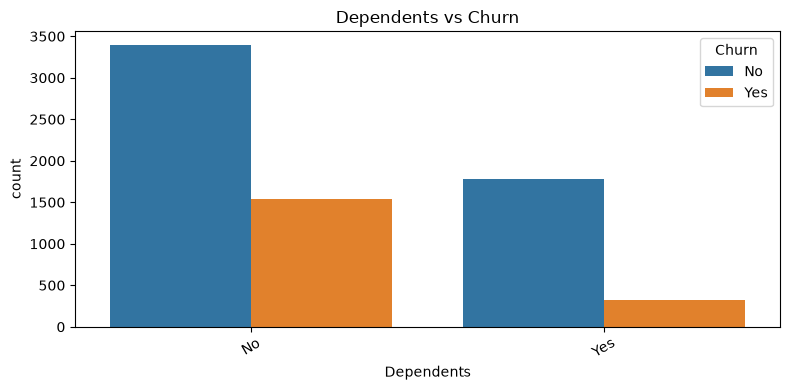

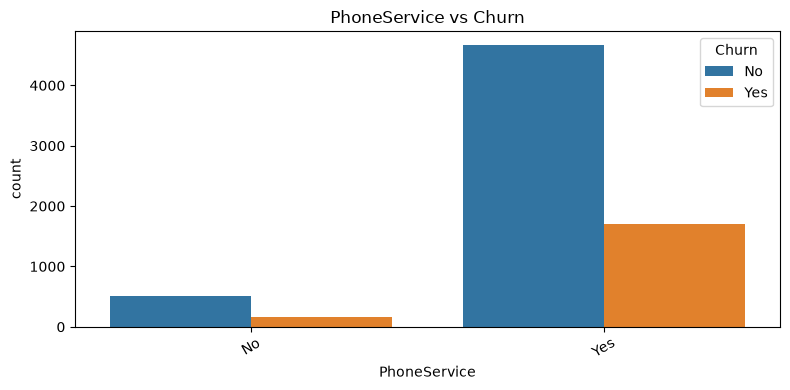

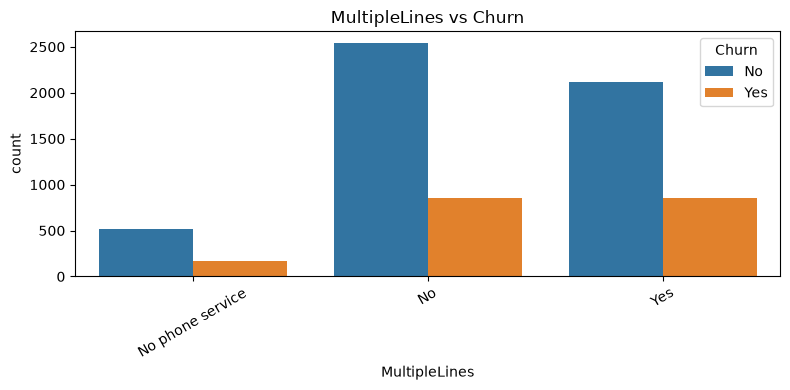

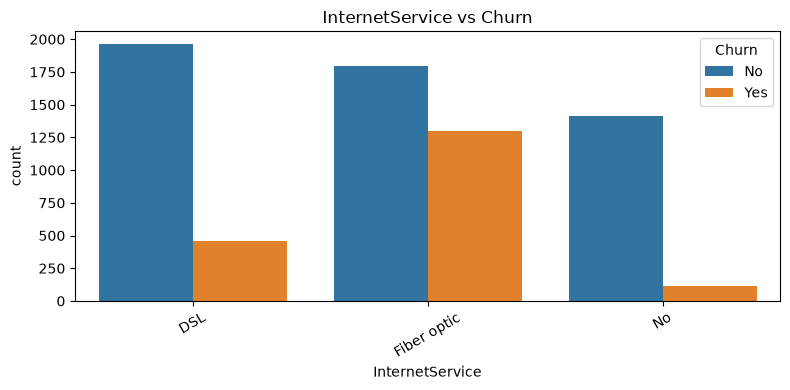

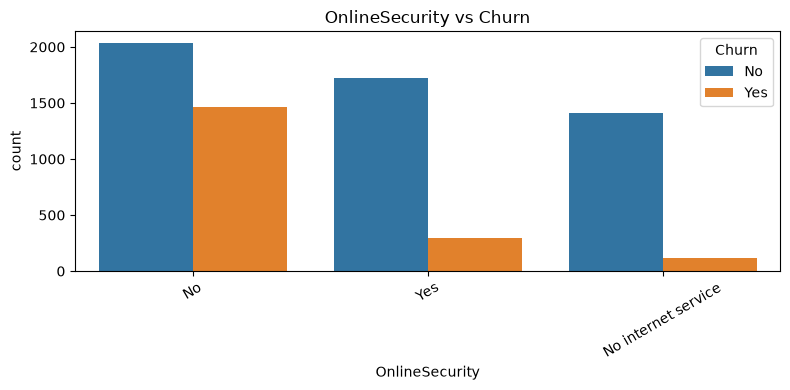

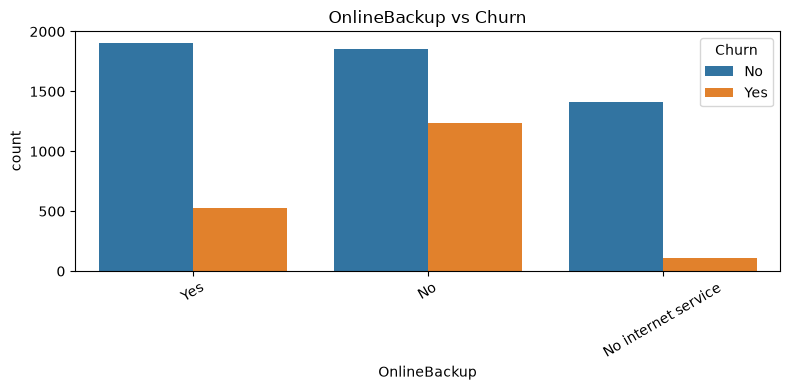

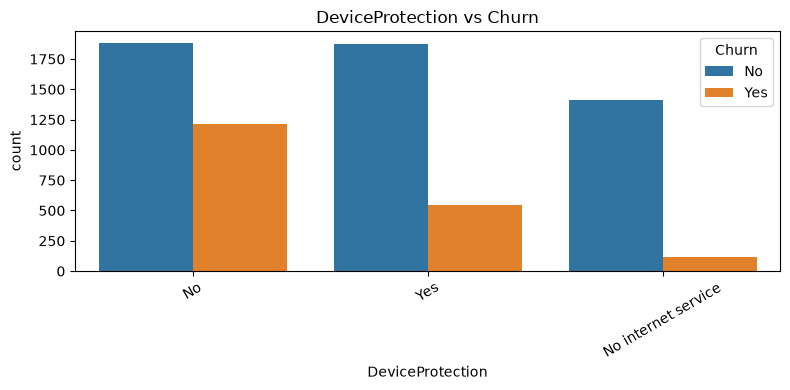

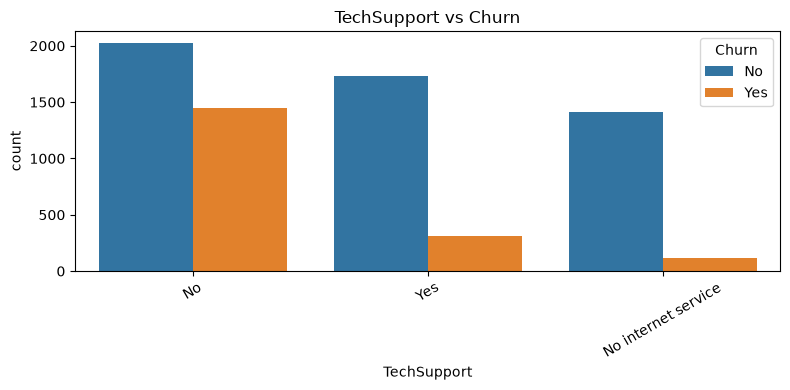

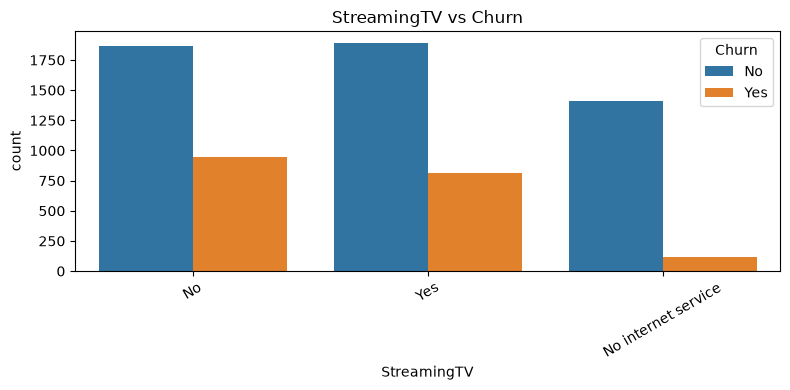

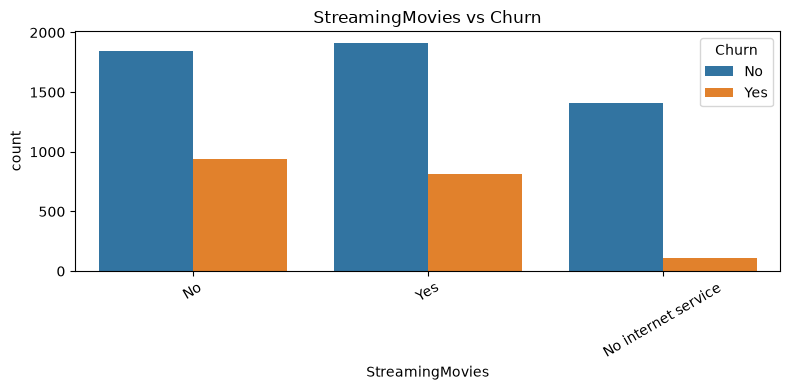

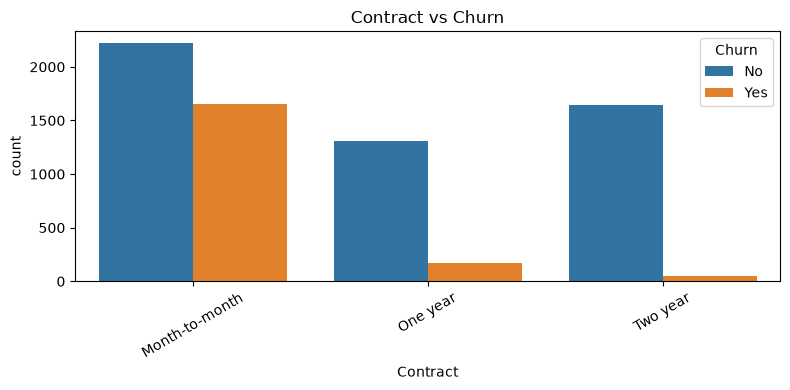

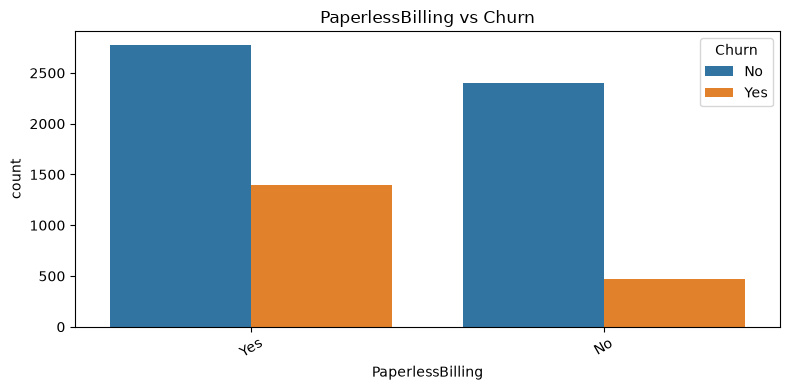

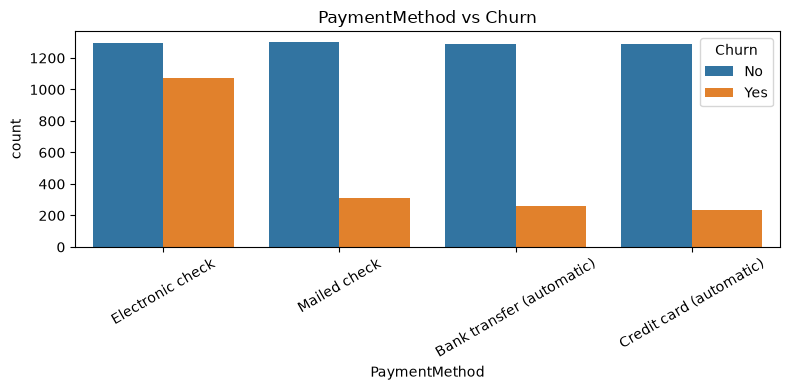

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in categorical_columns:
    plt.figure(figsize=(8, 4))
    
    sns.countplot(
        data=df,
        x=col,
        hue="Churn"
    )
    
    plt.title(f"{col} vs Churn")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()